<a href="https://colab.research.google.com/github/isaacgrindley/quantum-circuit-simulator/blob/main/QECMini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intro and setup
This project is a learning endevour that explores basic implementation of quantum circuits, and scratches the surface of Quantum Error Correction with a simple 3-qubit bit-flip code. In future, it may explore more complex methods of error correction, and study effectiveness of some quantum algorithms.

The following code block imports some necessary packages, before defining several functions that will be used throughout the project:
- **qReg(k)** creates a |0000> state of k qubits
- **measure(reg,n)** makes a complete measurement of a register n times, as if we had constructed the state in the register n times and then measured each of them
- **incMeasure(reg,i)** makes an incomplete projective measurement of the i<sup>th</sup> qubit in a register, returning the collapsed measured state along with the result of the measurement
- **plotMeasures(reg,n)** plots a histogram of the results of a complete measurement as implemented by measure(reg,n)
- **H(reg,i)**, **X(reg,i)**, **Y(reg,i)**,and **Z(reg,i)** act on the i<sup>th</sup> qubit of a register with the respective quantum gate
- **CX(reg,i,j)** acts on qubits i and j of a register, implementing CX with the i<sup>th</sup> qubit as the control and the j<sup>th</sup> as the target qubit


In [86]:
import numpy as np
import matplotlib.pyplot as plt
from math import *
from collections import Counter


def qReg(k):
  qbit = np.zeros((2**k,1))
  qbit[(0,0)] = 1
  return qbit

def normed(reg):
  normedreg = reg/sqrt((np.dot(reg.T.conjugate(),reg)).flatten()[0])
  return normedreg

def measure(reg,n):
  probs = abs(reg)**2
  result = []
  for i in range(n):
    iresult = int(np.random.choice(range(len(reg)),p = probs[:,0]))
    result.append(iresult)
  return result

def incMeasure(reg,i):
  proj0 = np.array([[1]])
  proj1 = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if i == k:
      proj0 = np.kron(proj0,np.array([[1,0],[0,0]]))
      proj1 = np.kron(proj1,np.array([[0,0],[0,1]]))
    else:
      proj0 = np.kron(proj0,np.array([[1,0],[0,1]]))
      proj1 = np.kron(proj1,np.array([[1,0],[0,1]]))
  prob0 = np.dot(reg.T.conjugate(),proj0 @ reg).real
  prob1 = np.dot(reg.T.conjugate(),proj1 @ reg).real
  probs = np.append(prob0,prob1)
  result = int(np.random.choice(range(2),p = probs))
  if result == 0:
    reg = (proj0 @ reg)/ np.sqrt(prob0)
  else:
    reg = (proj1 @ reg)/ np.sqrt(prob1)
  return result, reg

def plotMeasures(reg,n):
  plt.figure(figsize=(6,6))
  plt.hist(measure(reg,n),np.array(range(len(reg)+1))-0.5)
  plt.xlabel("Outcomes")
  plt.ylabel("Counts")
  labels = []
  for i in range(len(reg)):
    labels.append(np.binary_repr(i,int(log2(len(reg)))))
  plt.xticks(range(len(reg)),labels)
  plt.show
  return

def H(reg,i):
  H = 1/sqrt(2) * np.array([[1,1],[1,-1]])
  multiH = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiH = np.kron(multiH,H)
    else:
      multiH = np.kron(multiH,[[1,0],[0,1]])
  return multiH @ reg

def X(reg,i):
  X = np.array([[0,1],[1,0]])
  multiX = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiX = np.kron(multiX,X)
    else:
      multiX = np.kron(multiX,[[1,0],[0,1]])
  return multiX @ reg

def Y(reg,i):
  Y = np.array([[0,1],[-1,0]])
  multiY = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiY = np.kron(multiY,Y)
    else:
      multiY = np.kron(multiY,[[1,0],[0,1]])
  return multiY @ reg

def Z(reg,i):
  Z = np.array([[1,0],[0,-1]])
  multiZ = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      multiZ = np.kron(multiZ,Z)
    else:
      multiZ = np.kron(multiZ,[[1,0],[0,1]])
  return multiZ @ reg

def CX(reg,i,j):
  proj1 = np.array([[1]])
  proj2 = np.array([[1]])
  for k in range(int(log2(len(reg)))):
    if k == i:
      proj1 = np.kron(proj1,[[1,0],[0,0]])
      proj2 = np.kron(proj2,[[0,0],[0,1]])
    elif k == j:
      proj1 = np.kron(proj1,[[1,0],[0,1]])
      proj2 = np.kron(proj2,[[0,1],[1,0]])
    else:
      proj1 = np.kron(proj1,[[1,0],[0,1]])
      proj2 = np.kron(proj2,[[1,0],[0,1]])
    multiCX = proj1 + proj2
  return multiCX @ reg

# Measuring Bell states
Now we have the necessary scaffolding in place, we can construct the Bell states and do some measurements to test our simulator. The $\Phi_+$ state is constructed with a H and then CX gate and then applications of X or Z generate the other Bell states. We then plot the result of 1000 measurements of such a state to verify the behaviour we expect.

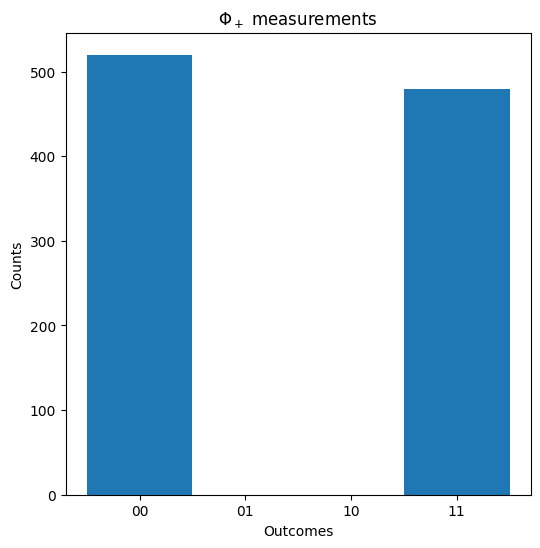

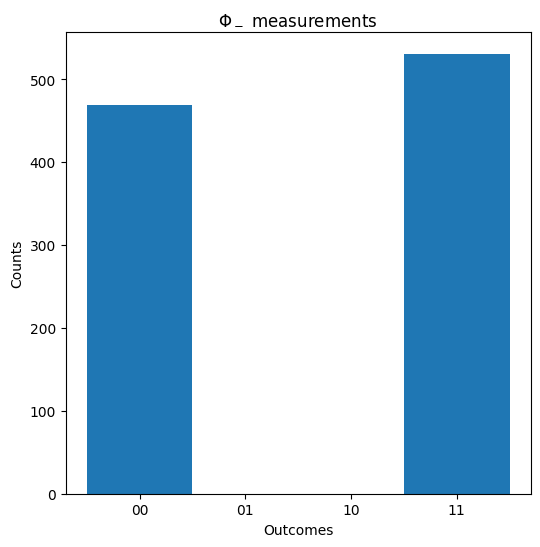

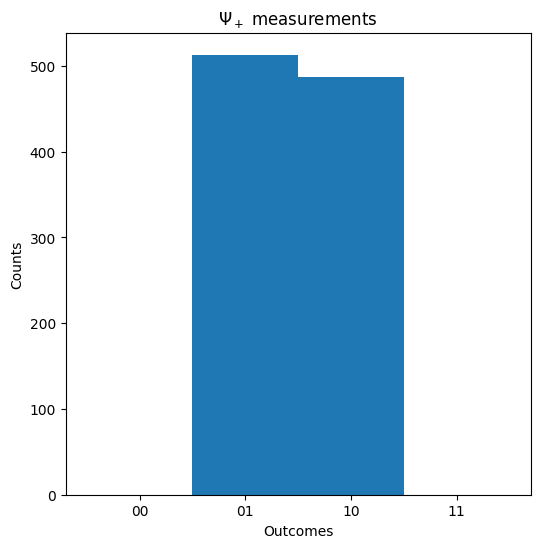

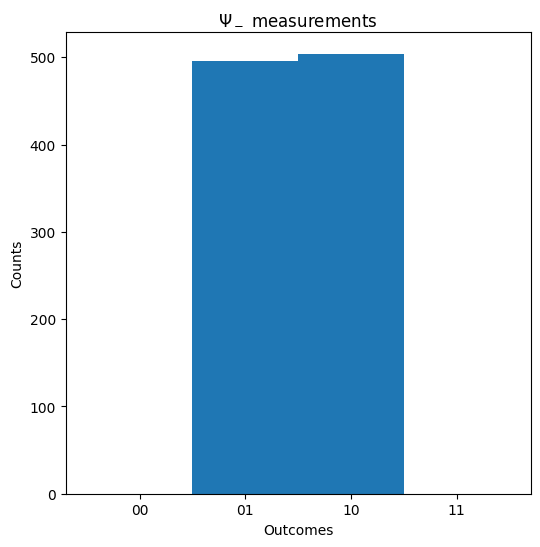

In [87]:
phiPlus = qReg(2)
phiMinus = qReg(2)
psiPlus = qReg(2)
psiMinus = qReg(2)

phiPlus = CX(H(phiPlus,0),0,1)
psiPlus = X(phiPlus,1)
phiMinus = Z(phiPlus,1)
psiMinus = Z(psiPlus,0)

plotMeasures(phiPlus,1000)
plt.title("$\\Phi_+$ measurements")
plotMeasures(phiMinus,1000)
plt.title("$\\Phi_-$ measurements")
plotMeasures(psiPlus,1000)
plt.title("$\\Psi_+$ measurements")
plotMeasures(psiMinus,1000)
plt.title("$\\Psi_-$ measurements")
print()

# A first look at QEC
Now let's explore some basic error correction. First we encode a single qubit into three $(a|0\rangle + b|1\rangle) \to (a|000\rangle + b|111\rangle)$ with the **encode3(qbit)** function. We introduce independent random bit flip errors using **flipBits(reg)**. We can then implement a parity check, using CX gates on ancillary qubits called the syndrome and making an incomplete projective measurement on these parity qubits (see **parityCheck(reg)**). Using this parity check, we make a correction using **correct1flip(reg)** with the assumption that only one bit flip has occurred.

In [88]:
def encode3(qbit):
  reg = np.kron(qReg(1),np.kron(qReg(1),qbit))
  # tensor products two 0 qubits to the qubit to make a 3-qubit register
  result = CX(reg,2,0)
  result = CX(result,2,1)
  return result

def flipBits(reg):
  p = 0.9
  flipprobs = np.random.rand(3)
  for i in range(3):
    if flipprobs[i] < p:
      reg = X(reg,i)
  return reg

def parityCheck(reg):
  #add 2 ancilliary qbits to store comparisons of (1st and 2nd) and (1st and 3rd) qubits
  reg = np.kron(np.kron(reg,np.array([[1],[0]])),np.array([[1],[0]]))
  reg = CX(reg,0,3)
  reg = CX(reg,1,3)
  reg = CX(reg,0,4)
  reg = CX(reg,2,4)
  pty1, reg = incMeasure(reg,3)
  pty2, reg = incMeasure(reg,4)
  result = str(pty1) + str(pty2)
  return result, reg

def correct1flip(pty, reg):
  if pty == "01":
    reg = X(reg,2)
    reg = reg[1::4]
  elif pty == "10":
    reg = X(reg,1)
    reg = reg[2::4]
  elif pty == "11":
    reg = X(reg,0)
    reg = reg[3::4]
  else:
    reg = reg[::4]
  return reg


qin = normed(np.array([[0.776 + 3j],[0.01 - 2j]]))
np.dot(qin.T.conjugate(),qin)
qcoded = encode3(qin)
qflipped = flipBits(qcoded)
print(qflipped)

ptyChk, qflipped = parityCheck(qflipped)
print(ptyChk)
print(correct1flip(ptyChk, qflipped))

[[0.0027114 -0.54228077j]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.21040494+0.81342116j]]
00
[[0.0027114 -0.54228077j]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.        +0.j        ]
 [0.21040494+0.81342116j]]


/tmp/ipykernel_860/883803536.py:13: ComplexWarning: Casting complex values to real discards the imaginary part
  normedreg = reg/sqrt((np.dot(reg.T.conjugate(),reg)).flatten()[0])
